In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import matplotlib.pyplot as plt
import time

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.5.1
Torchvision version: 0.20.1
CUDA available: True


In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download MNIST training dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download MNIST test dataset
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data\MNIST\raw\train-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data\MNIST\raw\train-labels-idx1-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data\MNIST\raw\t10k-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%

Extracting ./data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\MNIST\raw

Training images: 60000
Testing images: 10000
Image shape: torch.Size([1, 28, 28])


In [3]:
# Original LeNet CNN architecture

class LeNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Conv2d(6, 16, kernel_size=5),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Flatten(),

            nn.Linear(16 * 5 * 5, 120),
            nn.Sigmoid(),

            nn.Linear(120, 84),
            nn.Sigmoid(),

            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.network(x)


# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = LeNet().to(device)

print("Device:", device)
print(model)

C:\Users\singh\miniconda3\envs\torch\lib\site-packages\torch\cuda\__init__.py:235: UserWarning: 
NVIDIA GeForce RTX 5070 Laptop GPU with CUDA capability sm_120 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_50 sm_60 sm_61 sm_70 sm_75 sm_80 sm_86 sm_90.
If you want to use the NVIDIA GeForce RTX 5070 Laptop GPU GPU with PyTorch, please check the instructions at https://pytorch.org/get-started/locally/

  warnings.warn(


Device: cuda
LeNet(
  (network): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Sigmoid()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Sigmoid()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=400, out_features=120, bias=True)
    (8): Sigmoid()
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): Sigmoid()
    (11): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [4]:
# Temporarily use CPU because the installed PyTorch
# does not support the RTX 5070 GPU architecture

device = torch.device("cpu")
model = LeNet().to(device)

# Test the model with one batch of MNIST images
images, labels = next(iter(train_loader))

with torch.no_grad():
    outputs = model(images.to(device))

print("Device:", device)
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Device: cpu
Input shape: torch.Size([128, 1, 28, 28])
Output shape: torch.Size([128, 10])


In [5]:
# Baseline LeNet training

torch.manual_seed(42)

model = LeNet().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 5
baseline_start = time.perf_counter()

baseline_history = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    model.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            test_correct += (predictions == labels).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    baseline_history.append({
        "epoch": epoch + 1,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

baseline_time = time.perf_counter() - baseline_start

print(f"\nTotal baseline training and evaluation time: {baseline_time:.2f} seconds")

Epoch 1/5 | Loss: 1.4818 | Train Accuracy: 49.31% | Test Accuracy: 82.13%
Epoch 2/5 | Loss: 0.4086 | Train Accuracy: 88.34% | Test Accuracy: 91.22%
Epoch 3/5 | Loss: 0.2478 | Train Accuracy: 92.67% | Test Accuracy: 93.86%
Epoch 4/5 | Loss: 0.1846 | Train Accuracy: 94.39% | Test Accuracy: 95.60%
Epoch 5/5 | Loss: 0.1473 | Train Accuracy: 95.52% | Test Accuracy: 96.06%

Total baseline training and evaluation time: 146.12 seconds


In [6]:
# Experiment 1: LeNet with Max Pooling

class LeNetMaxPool(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2),
            nn.Sigmoid(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(6, 16, kernel_size=5),
            nn.Sigmoid(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Flatten(),

            nn.Linear(16 * 5 * 5, 120),
            nn.Sigmoid(),

            nn.Linear(120, 84),
            nn.Sigmoid(),

            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.network(x)


maxpool_model = LeNetMaxPool().to(device)

print("Max-pooling LeNet created successfully!")
print(maxpool_model)

Max-pooling LeNet created successfully!
LeNetMaxPool(
  (network): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Sigmoid()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Sigmoid()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=400, out_features=120, bias=True)
    (8): Sigmoid()
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): Sigmoid()
    (11): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [7]:
# Experiment 1: Train LeNet with Max Pooling

torch.manual_seed(42)

maxpool_model = LeNetMaxPool().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(maxpool_model.parameters(), lr=0.001)

maxpool_history = []
maxpool_start = time.perf_counter()

for epoch in range(5):
    maxpool_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = maxpool_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    maxpool_model.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = maxpool_model(images)
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    maxpool_history.append({
        "epoch": epoch + 1,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

maxpool_time = time.perf_counter() - maxpool_start

print(f"\nTotal max-pooling training and evaluation time: {maxpool_time:.2f} seconds")

Epoch 1/5 | Loss: 1.4642 | Train Accuracy: 50.04% | Test Accuracy: 84.23%
Epoch 2/5 | Loss: 0.3507 | Train Accuracy: 90.21% | Test Accuracy: 93.94%
Epoch 3/5 | Loss: 0.1830 | Train Accuracy: 94.68% | Test Accuracy: 96.25%
Epoch 4/5 | Loss: 0.1301 | Train Accuracy: 96.13% | Test Accuracy: 96.91%
Epoch 5/5 | Loss: 0.1029 | Train Accuracy: 96.91% | Test Accuracy: 97.55%

Total max-pooling training and evaluation time: 147.75 seconds


In [8]:
# Experiment 2: LeNet with ReLU at the output

class LeNetReLUOutput(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Conv2d(6, 16, kernel_size=5),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Flatten(),

            nn.Linear(16 * 5 * 5, 120),
            nn.Sigmoid(),

            nn.Linear(120, 84),
            nn.Sigmoid(),

            nn.Linear(84, 10),
            nn.ReLU()
        )

    def forward(self, x):
        return self.network(x)


relu_model = LeNetReLUOutput().to(device)

print("ReLU-output LeNet created successfully!")
print(relu_model)

ReLU-output LeNet created successfully!
LeNetReLUOutput(
  (network): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Sigmoid()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Sigmoid()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=400, out_features=120, bias=True)
    (8): Sigmoid()
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): Sigmoid()
    (11): Linear(in_features=84, out_features=10, bias=True)
    (12): ReLU()
  )
)


In [9]:
# Experiment 2: Train LeNet with ReLU output

torch.manual_seed(42)

relu_model = LeNetReLUOutput().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(relu_model.parameters(), lr=0.001)

relu_history = []
relu_start = time.perf_counter()

for epoch in range(5):
    relu_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = relu_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    relu_model.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = relu_model(images)
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    relu_history.append({
        "epoch": epoch + 1,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

relu_time = time.perf_counter() - relu_start

print(f"\nTotal ReLU-output training and evaluation time: {relu_time:.2f} seconds")

Epoch 1/5 | Loss: 2.1553 | Train Accuracy: 18.13% | Test Accuracy: 20.87%
Epoch 2/5 | Loss: 2.0797 | Train Accuracy: 20.76% | Test Accuracy: 20.82%
Epoch 3/5 | Loss: 2.0725 | Train Accuracy: 20.79% | Test Accuracy: 20.74%
Epoch 4/5 | Loss: 2.0669 | Train Accuracy: 20.81% | Test Accuracy: 21.00%
Epoch 5/5 | Loss: 2.0632 | Train Accuracy: 20.82% | Test Accuracy: 20.99%

Total ReLU-output training and evaluation time: 156.87 seconds


In [10]:
# Experiment 3a: LeNet with 3x3 convolution kernels

class LeNetSmallKernel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=3, padding=1),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Conv2d(6, 16, kernel_size=3, padding=0),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Flatten(),

            nn.Linear(16 * 6 * 6, 120),
            nn.Sigmoid(),

            nn.Linear(120, 84),
            nn.Sigmoid(),

            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.network(x)


smallkernel_model = LeNetSmallKernel().to(device)

# Verify output dimensions
sample_images, _ = next(iter(train_loader))

with torch.no_grad():
    sample_outputs = smallkernel_model(sample_images.to(device))

print("3x3 kernel LeNet created successfully!")
print("Output shape:", sample_outputs.shape)
print(smallkernel_model)

3x3 kernel LeNet created successfully!
Output shape: torch.Size([128, 10])
LeNetSmallKernel(
  (network): Sequential(
    (0): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): Sigmoid()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
    (4): Sigmoid()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=576, out_features=120, bias=True)
    (8): Sigmoid()
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): Sigmoid()
    (11): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [11]:
# Experiment 3a: Train LeNet with 3x3 kernels

torch.manual_seed(42)

smallkernel_model = LeNetSmallKernel().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(smallkernel_model.parameters(), lr=0.001)

smallkernel_history = []
smallkernel_start = time.perf_counter()

for epoch in range(5):
    smallkernel_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = smallkernel_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    smallkernel_model.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = smallkernel_model(images)
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    smallkernel_history.append({
        "epoch": epoch + 1,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

smallkernel_time = time.perf_counter() - smallkernel_start

print(
    f"\nTotal 3x3 kernel training and evaluation time: "
    f"{smallkernel_time:.2f} seconds"
)

Epoch 1/5 | Loss: 1.6354 | Train Accuracy: 43.76% | Test Accuracy: 83.05%
Epoch 2/5 | Loss: 0.4520 | Train Accuracy: 86.93% | Test Accuracy: 89.86%
Epoch 3/5 | Loss: 0.3110 | Train Accuracy: 90.60% | Test Accuracy: 91.67%
Epoch 4/5 | Loss: 0.2483 | Train Accuracy: 92.32% | Test Accuracy: 93.06%
Epoch 5/5 | Loss: 0.2104 | Train Accuracy: 93.58% | Test Accuracy: 94.26%

Total 3x3 kernel training and evaluation time: 151.22 seconds


In [12]:
# Experiment 3b: LeNet with three convolution layers

class LeNetThreeConv(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2),
            nn.Sigmoid(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Conv2d(6, 16, kernel_size=5),
            nn.Sigmoid(),

            # Additional convolution layer
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.Sigmoid(),

            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Flatten(),

            nn.Linear(16 * 5 * 5, 120),
            nn.Sigmoid(),

            nn.Linear(120, 84),
            nn.Sigmoid(),

            nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.network(x)


threeconv_model = LeNetThreeConv().to(device)

# Verify the output shape
sample_images, _ = next(iter(train_loader))

with torch.no_grad():
    sample_outputs = threeconv_model(sample_images.to(device))

print("Three-convolution-layer LeNet created successfully!")
print("Output shape:", sample_outputs.shape)
print(threeconv_model)

Three-convolution-layer LeNet created successfully!
Output shape: torch.Size([128, 10])
LeNetThreeConv(
  (network): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Sigmoid()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Sigmoid()
    (5): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): Sigmoid()
    (7): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (8): Flatten(start_dim=1, end_dim=-1)
    (9): Linear(in_features=400, out_features=120, bias=True)
    (10): Sigmoid()
    (11): Linear(in_features=120, out_features=84, bias=True)
    (12): Sigmoid()
    (13): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [13]:
# Experiment 3b: Train LeNet with 3 convolution layers

torch.manual_seed(42)

threeconv_model = LeNetThreeConv().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(threeconv_model.parameters(), lr=0.001)

threeconv_history = []
threeconv_start = time.perf_counter()

for epoch in range(5):
    threeconv_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = threeconv_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    threeconv_model.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = threeconv_model(images)
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    threeconv_history.append({
        "epoch": epoch + 1,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

threeconv_time = time.perf_counter() - threeconv_start

print(
    f"\nTotal three-convolution-layer training and evaluation time: "
    f"{threeconv_time:.2f} seconds"
)

Epoch 1/5 | Loss: 1.7739 | Train Accuracy: 36.47% | Test Accuracy: 77.18%
Epoch 2/5 | Loss: 0.4869 | Train Accuracy: 85.54% | Test Accuracy: 91.02%
Epoch 3/5 | Loss: 0.2683 | Train Accuracy: 92.13% | Test Accuracy: 93.70%
Epoch 4/5 | Loss: 0.1947 | Train Accuracy: 94.14% | Test Accuracy: 95.13%
Epoch 5/5 | Loss: 0.1559 | Train Accuracy: 95.28% | Test Accuracy: 95.61%

Total three-convolution-layer training and evaluation time: 173.40 seconds


In [14]:
# Experiment 3c: Change learning rate to 0.003

torch.manual_seed(42)

lr_model = LeNet().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(lr_model.parameters(), lr=0.003)

lr_history = []
lr_start = time.perf_counter()

for epoch in range(5):
    lr_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = lr_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    lr_model.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = lr_model(images)
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    lr_history.append({
        "epoch": epoch + 1,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

lr_time = time.perf_counter() - lr_start

print(
    f"\nTotal learning-rate experiment time: "
    f"{lr_time:.2f} seconds"
)

Epoch 1/5 | Loss: 0.9973 | Train Accuracy: 65.45% | Test Accuracy: 92.39%
Epoch 2/5 | Loss: 0.1914 | Train Accuracy: 94.19% | Test Accuracy: 96.06%
Epoch 3/5 | Loss: 0.1143 | Train Accuracy: 96.58% | Test Accuracy: 97.25%
Epoch 4/5 | Loss: 0.0824 | Train Accuracy: 97.45% | Test Accuracy: 98.09%
Epoch 5/5 | Loss: 0.0650 | Train Accuracy: 98.01% | Test Accuracy: 97.90%

Total learning-rate experiment time: 149.53 seconds


In [15]:
# Experiment 3c: Xavier weight initialization

def xavier_initialize(module):
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        nn.init.xavier_uniform_(module.weight)

        if module.bias is not None:
            nn.init.zeros_(module.bias)


torch.manual_seed(42)

xavier_model = LeNet().to(device)
xavier_model.apply(xavier_initialize)

print("Xavier initialization applied successfully!")
print("First convolution weight mean:",
      xavier_model.network[0].weight.mean().item())

Xavier initialization applied successfully!
First convolution weight mean: 0.005895234178751707


In [16]:
# Experiment 3c: Train LeNet with Xavier initialization

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(xavier_model.parameters(), lr=0.001)

xavier_history = []
xavier_start = time.perf_counter()

for epoch in range(5):
    xavier_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = xavier_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    xavier_model.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = xavier_model(images)
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    xavier_history.append({
        "epoch": epoch + 1,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

xavier_time = time.perf_counter() - xavier_start

print(
    f"\nTotal Xavier initialization training and evaluation time: "
    f"{xavier_time:.2f} seconds"
)

Epoch 1/5 | Loss: 1.5122 | Train Accuracy: 50.28% | Test Accuracy: 87.45%
Epoch 2/5 | Loss: 0.3515 | Train Accuracy: 90.07% | Test Accuracy: 92.12%
Epoch 3/5 | Loss: 0.2367 | Train Accuracy: 92.86% | Test Accuracy: 94.15%
Epoch 4/5 | Loss: 0.1841 | Train Accuracy: 94.45% | Test Accuracy: 95.30%
Epoch 5/5 | Loss: 0.1489 | Train Accuracy: 95.45% | Test Accuracy: 96.15%

Total Xavier initialization training and evaluation time: 140.22 seconds


In [17]:
# Experiment 3c: Train original LeNet for 10 epochs

torch.manual_seed(42)

epochs_model = LeNet().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(epochs_model.parameters(), lr=0.001)

epochs_history = []
epochs_start = time.perf_counter()

for epoch in range(10):
    epochs_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = epochs_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    epochs_model.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = epochs_model(images)
            test_correct += (outputs.argmax(dim=1) == labels).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    epochs_history.append({
        "epoch": epoch + 1,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy
    })

    print(
        f"Epoch {epoch + 1}/10 | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

epochs_time = time.perf_counter() - epochs_start

print(
    f"\nTotal 10-epoch training and evaluation time: "
    f"{epochs_time:.2f} seconds"
)

Epoch 1/10 | Loss: 1.4818 | Train Accuracy: 49.31% | Test Accuracy: 82.13%
Epoch 2/10 | Loss: 0.4086 | Train Accuracy: 88.34% | Test Accuracy: 91.22%
Epoch 3/10 | Loss: 0.2478 | Train Accuracy: 92.67% | Test Accuracy: 93.86%
Epoch 4/10 | Loss: 0.1846 | Train Accuracy: 94.39% | Test Accuracy: 95.60%
Epoch 5/10 | Loss: 0.1473 | Train Accuracy: 95.52% | Test Accuracy: 96.06%
Epoch 6/10 | Loss: 0.1236 | Train Accuracy: 96.28% | Test Accuracy: 96.70%
Epoch 7/10 | Loss: 0.1081 | Train Accuracy: 96.78% | Test Accuracy: 97.01%
Epoch 8/10 | Loss: 0.0922 | Train Accuracy: 97.21% | Test Accuracy: 97.30%
Epoch 9/10 | Loss: 0.0839 | Train Accuracy: 97.43% | Test Accuracy: 97.66%
Epoch 10/10 | Loss: 0.0752 | Train Accuracy: 97.73% | Test Accuracy: 97.61%

Total 10-epoch training and evaluation time: 293.04 seconds


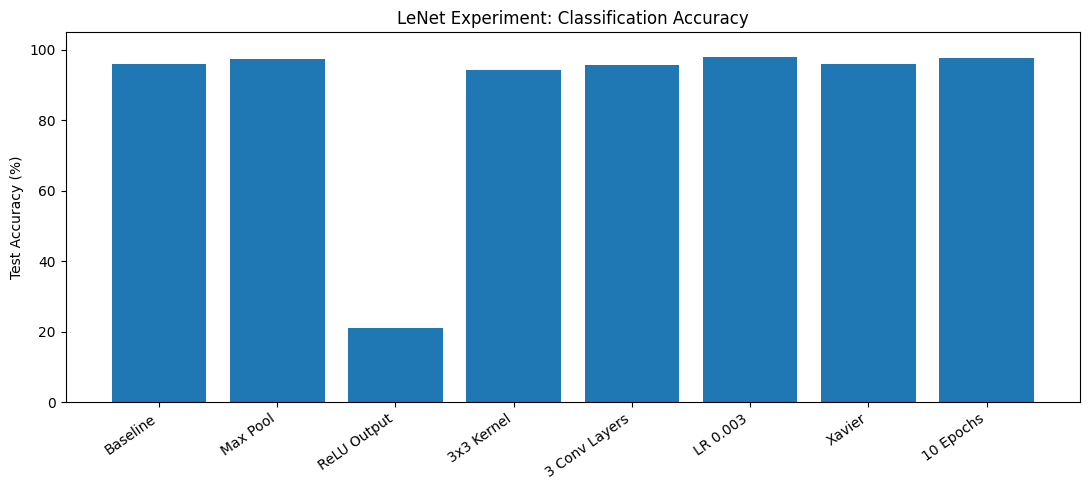

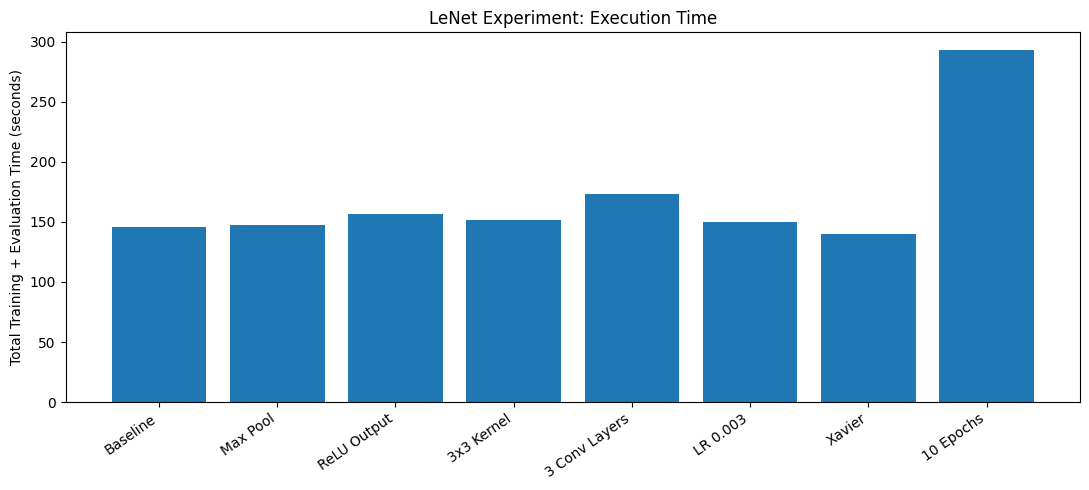

In [18]:
import matplotlib.pyplot as plt

experiments = [
    "Baseline", "Max Pool", "ReLU Output", "3x3 Kernel",
    "3 Conv Layers", "LR 0.003", "Xavier", "10 Epochs"
]

accuracies = [
    96.06, 97.55, 20.99, 94.26,
    95.61, 97.90, 96.15, 97.61
]

times = [
    146.12, 147.75, 156.87, 151.22,
    173.40, 149.53, 140.22, 293.04
]

plt.figure(figsize=(11, 5))
plt.bar(experiments, accuracies)
plt.ylabel("Test Accuracy (%)")
plt.title("LeNet Experiment: Classification Accuracy")
plt.ylim(0, 105)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("lenet_accuracy_comparison.png", dpi=300)
plt.show()

plt.figure(figsize=(11, 5))
plt.bar(experiments, times)
plt.ylabel("Total Training + Evaluation Time (seconds)")
plt.title("LeNet Experiment: Execution Time")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("lenet_training_time_comparison.png", dpi=300)
plt.show()